In [1]:
import mplhep as hep
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot as ur

from utils.labels import (
    luminosity
)

In [2]:
channel_US = "ggH"
bkg_file = "../root_io/tuples/BDT_score/" + channel_US + "/BFull_SNottH/background_Combined.root"
#bkg_file = "../root_io/tuples/DY_Combined_tuples.root"
sig_file = "../root_io/tuples/BDT_score/" + channel_US + "/BFull_SNottH/signal_Combined.root"

In [3]:
with ur.open(sig_file+":tree_output") as file:
    print(file.keys())

['gen_weight', 'pileup_weight', 'pileup_weight_up', 'pileup_weight_down', 'scale_factor', 'weight', 'weight_no_eff_sf', 'weight_no_lumi', 'rho', 'PV', 'mu_trig_eff_SF', 'mu_trig_eff_SF_down', 'mu_trig_eff_SF_up', 'mu_ID_eff_SF', 'mu_ID_eff_SF_down', 'mu_ID_eff_SF_up', 'mu_ISO_eff_SF', 'mu_ISO_eff_SF_down', 'mu_ISO_eff_SF_up', 'n_SoftJet_pt2', 'n_SoftJet_pt5', 'n_SoftJet_pt10', 'HT', 'HT_pt2', 'HT_pt5', 'HT_pt10', 'is_ggH_category', 'is_VBF_category', 'mc_campaign', 'channel', 'diMuon_mass', 'diMuon_bsConstrainedMass_nanoAOD', 'diMuon_bsConstrainedMass', 'diMuon_pt', 'diMuon_bsConstrainedPt', 'diMuon_phi', 'diMuon_eta', 'diMuon_rapidity', 'PuppiMET_phi', 'PuppiMET_pt', 'PuppiMET_sumEt', 'mu1_pt_mass_ratio', 'mu2_pt_mass_ratio', 'mu1_bsConstrainedPt_mass_ratio', 'mu2_bsConstrainedPt_mass_ratio', 'mu1_eta', 'mu2_eta', 'mu1_pt', 'mu2_pt', 'mu1_bsConstrainedPt_nanoAOD', 'mu2_bsConstrainedPt_nanoAOD', 'mu1_bsConstrainedPt', 'mu2_bsConstrainedPt', 'mu1_ptErr', 'mu2_ptErr', 'mu1_bsConstrainedP

In [4]:
bkg_tree = ur.open(bkg_file+":tree_output")
sig_tree = ur.open(sig_file+":tree_output")

In [5]:
diMuon_mass_bsC_bkg = bkg_tree["diMuon_bsConstrainedMass"].array(library='np')
bkg_weight = bkg_tree["weight"].array(library='np')
diMuon_mass_bsC_sig = sig_tree["diMuon_bsConstrainedMass"].array(library='np')
sig_weight = bkg_tree["weight"].array(library='np')
BDT_bkg = bkg_tree["BDT_"+channel_US].array(library='np')
BDT_sig = sig_tree["BDT_"+channel_US].array(library='np')

/cvmfs/cms.cern.ch/el9_amd64_gcc12/external/py3-numpy/1.24.3-a3a65cbc18c6a98e06451d4329e3ea47/lib/python3.9/site-packages/numpy/core/getlimits.py:518: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  setattr(self, word, getattr(machar, word).flat[0])
/cvmfs/cms.cern.ch/el9_amd64_gcc12/external/py3-numpy/1.24.3-a3a65cbc18c6a98e06451d4329e3ea47/lib/python3.9/site-packages/numpy/core/getlimits.py:89: UserWarning: The value of the smallest subnormal for <class 'numpy.float64'> type is zero.
  return self._float_to_str(self.smallest_subnormal)


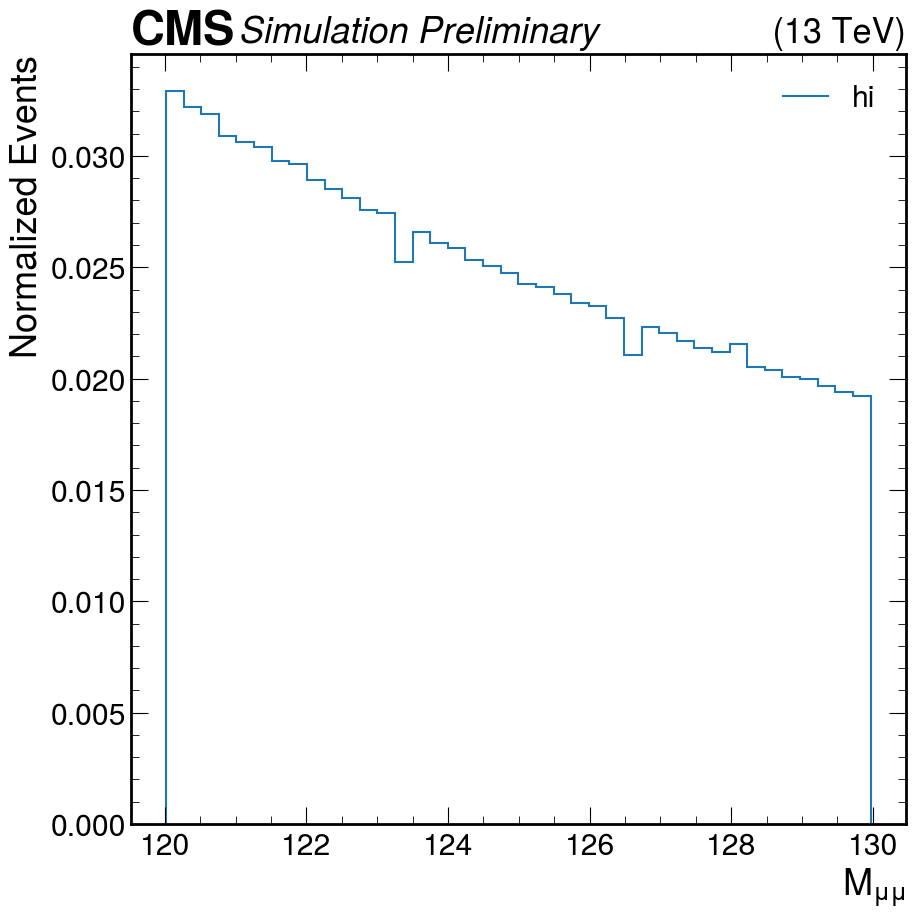

In [6]:
mask = (BDT_bkg > 0) & (BDT_bkg < 1) & (diMuon_mass_bsC_bkg > 120) & (diMuon_mass_bsC_bkg < 130)
hep.style.use("CMS")

counts, bins = np.histogram(diMuon_mass_bsC_bkg[mask], bins=40, weights=bkg_weight[mask])
counts = counts / counts.sum()
fig, ax = plt.subplots()

hep.histplot(counts, bins=bins, ax=ax, label="hi")
hep.cms.label("Preliminary", data=False, com=13) 
ax.set_xlabel('$M_{\mu\mu}$')
ax.set_ylabel('Normalized Events')
ax.legend()

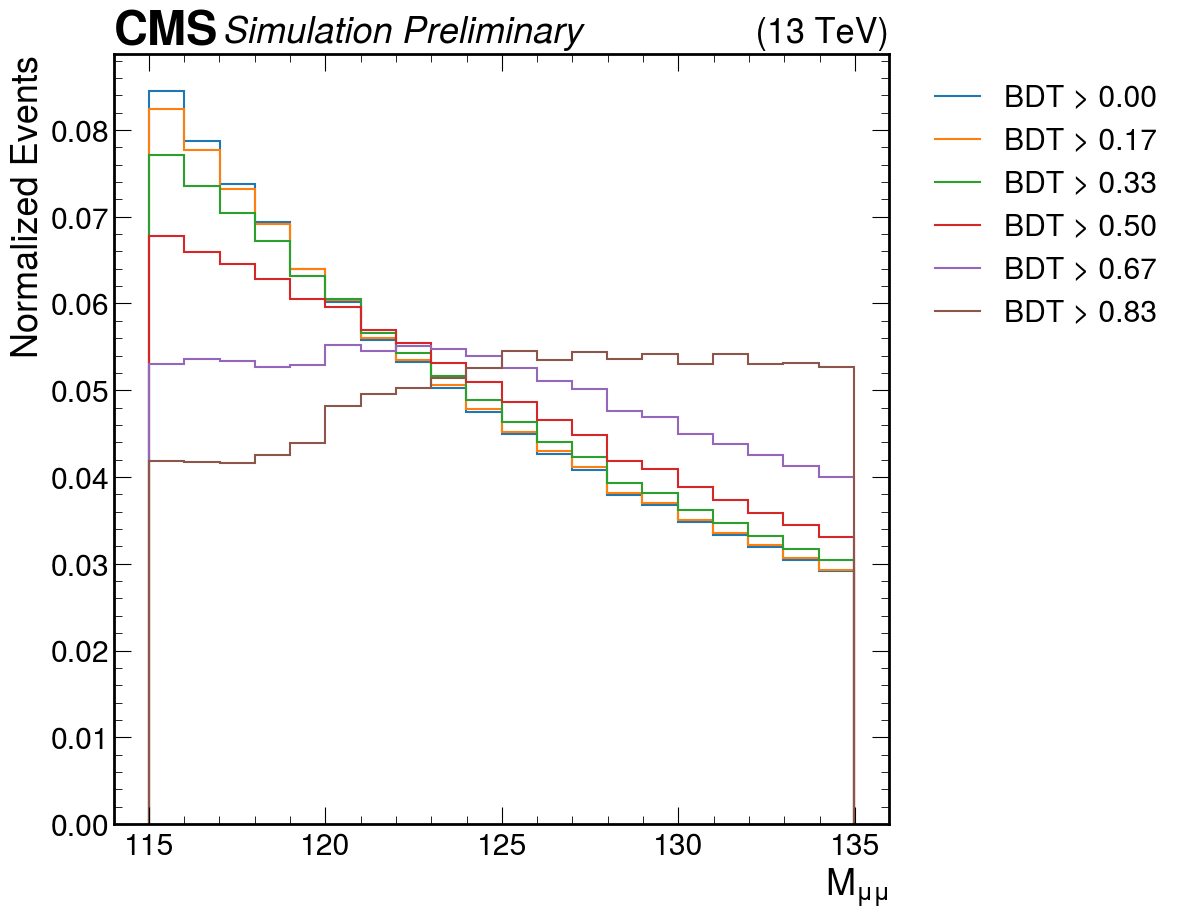

In [7]:
bdt_divisions = 6
mass_low = 115
mass_high = 135
hep.style.use("CMS")

fig, ax = plt.subplots()

hep.cms.label("Preliminary", data=False, com=13) 
ax.set_xlabel('$M_{\mu\mu}$')
ax.set_ylabel('Normalized Events')

for bdt_cut in np.linspace(0,1-1/bdt_divisions,bdt_divisions):
    bdt_spacing = 1/bdt_divisions
    bdt_low = bdt_cut
    bdt_high = bdt_low + bdt_spacing
    
    mask = (BDT_bkg > bdt_low) & (diMuon_mass_bsC_bkg > mass_low) & (diMuon_mass_bsC_bkg < mass_high)
    hep.style.use("CMS")

    counts, bins = np.histogram(diMuon_mass_bsC_bkg[mask], bins=20, weights=bkg_weight[mask])
    counts = counts / counts.sum()

    hep.histplot(counts, bins=bins, ax=ax, label=f"BDT > {bdt_low:.2f}")

#ax.legend()
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
#plt.show()
#plt.savefig('../plots/sculpting_study/preOptunaBkgVBFscuplting.png', bbox_inches="tight")
#plt.savefig('../plots/sculpting_study/preOptunaBkgVBFscuplting.pdf', bbox_inches="tight")